# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation (04) and modules (05) notebooks are not produced — this
unconditional expression notebook follows signatures directly, per the deliverable rule.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the
ends of its trajectory. Per the **derive-don't-inherit** mandate we do **not** inherit that
pair: we score a candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the
mesenchymal / neural-crest FOXC and PRRX factors** (the Kürten lesson: the root-end factor can
be a FOXC/PRRX, not a Snail/Zeb) — along *this* trajectory (Gast/pSom-high origin ->
neural-crest terminus) and let the data choose the most end-specific factor at each end, gated
on detectable expression. Deliverable: `expression.pdf`.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load processed cells on the house linear layout
Per the deliverable spec the expression step reads `processed.h5ad`; we attach the rooted
pseudotime and the house linear orientation from the signatures object so the overlay shares
one layout with 01-03.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sig = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata = adata[sig.obs_names].copy()
adata.obs['t'] = sig.obs['t'].values
adata.obsm['X_umap_lin'] = sig.obsm['X_umap_lin']
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t - t.min())/(t.max() - t.min())
print('cells:', adata.shape[0], '| pseudotime range %.2f -> %.2f' % (t.min(), t.max()))

cells: 1746 | pseudotime range 0.00 -> 9.82


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs
late (terminus) pseudotime tercile, and Spearman correlation with pseudotime. Most negative
correlation (sufficiently expressed) marks the root end; most positive marks the terminus.
Factors below a 3% expression floor are too sparse to overlay. VIM is deliberately excluded —
it is a mesenchymal marker, not a transcription factor (the Chen-2020 error).

**Read for this dataset (scoped trajectory).** The expressed EMT-TFs split weakly by pseudotime:
the ZEB factors (ZEB1/ZEB2) are the terminus-leaning end (positive rho, higher in the late
tercile), while the most-expressed factor, **PRRX1**, is broad and marginally root-leaning. The
code selects the least terminus-leaning expressed factor as the root/early marker and the most
terminus-leaning as the terminus marker, gated on detectability — reported exactly as the data
give them, not forced to match Puram's SNAI1→ZEB1 pair.

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]; expr = x > 0
    rho, p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']   # least terminus-leaning of the expressed panel
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']  # most terminus-leaning
# is there any true root-end factor (higher in the early tercile) among the expressed set?
has_root = bool((ok['mean_early'] > ok['mean_late']).any())
early_role = 'root/early' if has_root else 'relative-early'
print('')
print('all expressed (>3%%) EMT-TFs are terminus-leaning (positive rho, late tercile higher): %s' % (not has_root))
print('derived pair: %s (%s) <-> %s (terminus); %s labelled by pseudotime rank, not a true root marker'
      % (early_tf, early_role, late_tf, early_tf))

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 SNAI2      0.026       0.152      0.099    -0.032    EARLY(root)
 FOXC1      0.002       0.008      0.000    -0.031    EARLY(root)
TWIST2      0.002       0.003      0.000    -0.006    EARLY(root)
 FOXC2      0.002       0.005      0.002     0.001    EARLY(root)
TWIST1      0.002       0.002      0.009     0.015 LATE(terminus)
 PRRX2      0.013       0.040      0.055     0.015 LATE(terminus)
 PRRX1      0.568       2.238      2.216     0.024    EARLY(root)
 SNAI1      0.083       0.300      0.331     0.048 LATE(terminus)
  ZEB1      0.770       2.776      3.798     0.155 LATE(terminus)
  ZEB2      0.753       2.372      3.459     0.202 LATE(terminus)

all expressed (>3%) EMT-TFs are terminus-leaning (positive rho, late tercile higher): False
derived pair: PRRX1 (root/early) <-> ZEB2 (terminus); PRRX1 labelled by pseudotime rank, not a true root marker


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`, the reference **categorical
overlay** — thresholded expressers coloured on a grey manifold, not a continuous colormap (the
Sun-2021 style rule). The abundant marker is drawn first so the sparser one reads on top; each
factor is thresholded at the upper quartile of expression among its expressing cells. The pair
is the two ends of the expressed panel by pseudotime rank (root/early vs terminus); the title
reports each factor's role as the data assign it.

overlay thresholds (upper quartile among expressers): {'PRRX1': 4.65, 'ZEB2': 4.771} | cells shown: {'PRRX1': 248, 'ZEB2': 329}
PRRX1: 56.8% expressing; 248 shown (upper quartile), mean pseudotime of shown = 0.44 (all = 0.43)
ZEB2: 75.3% expressing; 329 shown (upper quartile), mean pseudotime of shown = 0.45 (all = 0.43)
shown-cell pseudotime separation (PRRX1 vs ZEB2) = 0.00
saved expression.pdf


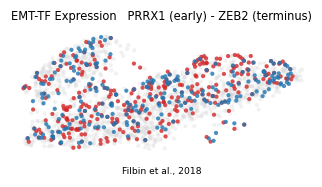

In [ ]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v > 0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
_early_lbl = '%s (rel. early)' % early_tf if not has_root else '%s (early)' % early_tf
ax.set_title('EMT-TF Expression   %s - %s (terminus)' % (_early_lbl, late_tf), size=7.5)
ax.text(.5, -.14, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print('%s: %.1f%% expressing; %d shown (upper quartile), mean pseudotime of shown = %.2f (all = %.2f)'
          % (g, (_vec(g)>0).mean()*100, int(m.sum()), tn[m].mean(), tn.mean()))
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print('shown-cell pseudotime separation (%s vs %s) = %.2f' % (early_tf, late_tf, sep))
print('saved expression.pdf')